In [1]:
!pip install fastdtw pandas numpy scipy scikit-learn catboost mediapipe opencv-python matplotlib seaborn



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import sys
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from fastdtw import fastdtw
from scipy.spatial.distance import euclidean
from catboost import CatBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings('ignore')
np.random.seed(42)

print("=" * 70)
print("             THÔNG TIN PHẦN CỨNG & MÔI TRƯỜNG THỰC NGHIỆM            ")
print("=" * 70)
print(f"Hệ điều hành          : {platform.system()} {platform.release()} ({platform.architecture()[0]})")
print(f"Bộ vi xử lý (CPU)     : {platform.processor() or platform.machine()}")
print(f"Số nhân CPU logic     : {os.cpu_count()} cores")
print(f"Phiên bản Python      : {platform.python_version()}")
print(f"Thư viện NumPy        : {np.__version__}")
print(f"Thư viện Pandas       : {pd.__version__}")
try:
    import mediapipe as mp
    print(f"Thư viện MediaPipe    : {mp.__version__}")
except Exception:
    pass
try:
    import cv2
    print(f"Thư viện OpenCV       : {cv2.__version__}")
except Exception:
    pass
print("=" * 70)


             THÔNG TIN PHẦN CỨNG & MÔI TRƯỜNG THỰC NGHIỆM            
Hệ điều hành          : Windows 11 (64bit)
Bộ vi xử lý (CPU)     : Intel64 Family 6 Model 154 Stepping 3, GenuineIntel
Số nhân CPU logic     : 16 cores
Phiên bản Python      : 3.13.0
Thư viện NumPy        : 2.3.3
Thư viện Pandas       : 2.3.2
Thư viện MediaPipe    : 1.2.2
Thư viện OpenCV       : 5.0.0


## 1. BENCHMARK MODULE 1: ƯỚC LƯỢNG TƯ THẾ (POSE ESTIMATION)

Trong hệ thống đánh giá chuyển động múa, module trích xuất khung xương đóng vai trò là đầu vào tiên quyết.
- **MediaPipe Pose (Google):** Sử dụng mạng nơ-ron tích chập nhẹ (Lite/Full) tối ưu bằng TensorFlow Lite XNNPACK trên CPU, dự đoán 33 điểm mốc cơ thể (trích xuất 13 khớp giải phẫu chính cho bài toán).
- **So sánh lý thuyết với OpenPose (CMU):** OpenPose dựa trên mô hình Bottom-Up Part Affinity Fields (PAF). Trên cùng cấu hình CPU, OpenPose thường mất từ **$500 - 1500$ ms/khung hình** (chỉ đạt 1-2 FPS, không khả thi cho tương tác thời gian thực); trên GPU chuyên dụng (NVIDIA RTX) OpenPose đạt khoảng **$30 - 60$ ms/khung hình** (15-30 FPS).
- Dưới đây là đo đạc thực nghiệm độ trễ xử lý thực tế của MediaPipe Pose trên luồng khung hình chuẩn ($640 \times 480$ và $1280 \times 720$).


In [3]:
import cv2
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision

MODEL_TASK_PATH = "pose_landmarker_lite.task"

# Khởi tạo MediaPipe Tasks PoseLandmarker
base_options = mp_python.BaseOptions(model_asset_path=MODEL_TASK_PATH)
options = mp_vision.PoseLandmarkerOptions(
    base_options=base_options,
    running_mode=mp_vision.RunningMode.IMAGE,
    num_poses=1
)
detector = mp_vision.PoseLandmarker.create_from_options(options)

# Tạo khung hình mẫu RGB (mô phỏng webcam 640x480 và HD 1280x720)
frame_vga = np.random.randint(0, 256, (480, 640, 3), dtype=np.uint8)
frame_hd = np.random.randint(0, 256, (720, 1280, 3), dtype=np.uint8)

mp_img_vga = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_vga)
mp_img_hd = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_hd)

# Warm-up 10 lần để nạp mô hình vào cache CPU
for _ in range(10):
    _ = detector.detect(mp_img_vga)

# Đo đạc 100 lần trên độ phân giải VGA 640x480
N_RUNS = 100
t_vga_list = []
for _ in range(N_RUNS):
    t0 = time.perf_counter()
    _ = detector.detect(mp_img_vga)
    t_vga_list.append((time.perf_counter() - t0) * 1000)

# Đo đạc 50 lần trên độ phân giải HD 1280x720
t_hd_list = []
for _ in range(50):
    t0 = time.perf_counter()
    _ = detector.detect(mp_img_hd)
    t_hd_list.append((time.perf_counter() - t0) * 1000)

t_pose_mean = np.mean(t_vga_list)
t_pose_std = np.std(t_vga_list)
t_pose_fps = 1000.0 / t_pose_mean

print("=== KẾT QUẢ ĐO ĐẠC MODULE 1: POSE ESTIMATION (MEDIAPIPE) ===")
print(f"- Độ phân giải VGA (640x480)   : {t_pose_mean:.2f} ms ± {t_pose_std:.2f} ms (Min: {np.min(t_vga_list):.2f} ms, Max: {np.max(t_vga_list):.2f} ms)")
print(f"  -> Tốc độ độc lập (Module FPS): {t_pose_fps:.1f} FPS")
print(f"- Độ phân giải HD (1280x720)   : {np.mean(t_hd_list):.2f} ms ± {np.std(t_hd_list):.2f} ms -> {1000.0/np.mean(t_hd_list):.1f} FPS")
print("\n* So sánh tham chiếu OpenPose (CPU): ~500 - 1500 ms/khung hình (1 - 2 FPS, quá chậm cho thời gian thực).")
print(f"* MediaPipe Pose nhanh hơn OpenPose trên CPU xấp xỉ {500 / t_pose_mean:.1f}x - {1500 / t_pose_mean:.1f}x lần.")


=== KẾT QUẢ ĐO ĐẠC MODULE 1: POSE ESTIMATION (MEDIAPIPE) ===
- Độ phân giải VGA (640x480)   : 13.74 ms ± 1.17 ms (Min: 11.68 ms, Max: 17.80 ms)
  -> Tốc độ độc lập (Module FPS): 72.8 FPS
- Độ phân giải HD (1280x720)   : 14.37 ms ± 2.33 ms -> 69.6 FPS

* So sánh tham chiếu OpenPose (CPU): ~500 - 1500 ms/khung hình (1 - 2 FPS, quá chậm cho thời gian thực).
* MediaPipe Pose nhanh hơn OpenPose trên CPU xấp xỉ 36.4x - 109.2x lần.


## 2. BENCHMARK MODULE 2: TIỀN XỬ LÝ & CĂN CHỈNH THỜI GIAN (FASTDTW)

FastDTW được sử dụng để gióng hàng chuỗi thời gian giữa chuyển động của học viên và động tác mẫu của giáo viên.
Chúng ta đo đạc thời gian xử lý trong 2 ngữ cảnh ứng dụng thực tế:
1. **Offline / Batch Mode (Đánh giá sau khi quay xong):** Gióng hàng toàn bộ 2 chuỗi video (~500 khung hình của học viên và giáo viên). Đo tổng thời gian và quy đổi sang độ trễ tính trên từng khung hình (*ms / khung hình*).
2. **Online / Streaming Mode (Tương tác thời gian thực / Unity):** Gióng hàng cửa sổ trượt cục bộ (*Sliding Window* $W = 30$ khung hình tương đương 1 giây chuyển động) để tìm khung hình giáo viên tương ứng trực tiếp tại thời điểm hiện tại.


In [4]:
# Nạp dữ liệu chuỗi khớp thực tế từ student_dance_1 và teacher_dance_1
df_s = pd.read_csv("student_dance_1.csv")
df_t = pd.read_csv("teacher_dance_1.csv")

def get_vectors(df):
    wide = df.pivot(index='Frame', columns='Joint_Name', values=['X', 'Y']).fillna(0)
    return wide.values

vec_s = get_vectors(df_s)  # Chuỗi 486 frames x 26 tọa độ
vec_t = get_vectors(df_t)  # Chuỗi 506 frames x 26 tọa độ

# 1. Batch FastDTW: Toàn bộ video bài múa (~500 khung hình)
t_batch_list = []
for _ in range(10):
    t0 = time.perf_counter()
    _, path = fastdtw(vec_s, vec_t, dist=euclidean)
    t_batch_list.append((time.perf_counter() - t0) * 1000)

t_batch_total = np.mean(t_batch_list)
t_dtw_batch_per_frame = t_batch_total / len(vec_s)

# 2. Streaming / Windowed FastDTW: Cửa sổ trượt 30 khung hình (1 giây)
WINDOW_SIZE = 30
window_s = vec_s[-WINDOW_SIZE:]
window_t = vec_t[-WINDOW_SIZE:]

t_win_list = []
for _ in range(100):
    t0 = time.perf_counter()
    _ = fastdtw(window_s, window_t, dist=euclidean)
    t_win_list.append((time.perf_counter() - t0) * 1000)

t_dtw_streaming = np.mean(t_win_list)
t_dtw_streaming_std = np.std(t_win_list)

print("=== KẾT QUẢ ĐO ĐẠC MODULE 2: ALIGNMENT (FASTDTW) ===")
print(f"1. Chế độ Batch (Chuỗi đầy đủ {len(vec_s)} x {len(vec_t)} khung hình):")
print(f"   - Tổng thời gian gióng hàng : {t_batch_total:.2f} ms")
print(f"   - Độ trễ trung bình/khung   : {t_dtw_batch_per_frame:.4f} ms/khung hình")
print(f"\n2. Chế độ Streaming (Cửa sổ trượt W = {WINDOW_SIZE} khung hình ~ 1.0 giây):")
print(f"   - Độ trễ gióng hàng thời gian thực: {t_dtw_streaming:.2f} ms ± {t_dtw_streaming_std:.2f} ms")
print(f"   - Tốc độ tương đương              : {1000.0 / t_dtw_streaming:.1f} FPS")


=== KẾT QUẢ ĐO ĐẠC MODULE 2: ALIGNMENT (FASTDTW) ===
1. Chế độ Batch (Chuỗi đầy đủ 486 x 506 khung hình):
   - Tổng thời gian gióng hàng : 65.79 ms
   - Độ trễ trung bình/khung   : 0.1354 ms/khung hình

2. Chế độ Streaming (Cửa sổ trượt W = 30 khung hình ~ 1.0 giây):
   - Độ trễ gióng hàng thời gian thực: 2.15 ms ± 0.32 ms
   - Tốc độ tương đương              : 464.2 FPS


## 3. BENCHMARK MODULE 3: TRÍCH XUẤT 3 ĐẶC TRƯNG HÌNH HỌC & ĐỘNG LỰC HỌC

Module này nhận tọa độ 13 khớp đã chuẩn hóa gốc hông và tỷ lệ thân người, sau đó tính toán đồng thời 3 đặc trưng cho 13 khớp trên khung hình hiện tại:
1. **Sai số khoảng cách Euclidean (`Joint_Error`):** $e_j = \sqrt{(X_s - X_t)^2 + (Y_s - Y_t)^2}$
2. **Độ tương đồng Cosine (`Joint_Cosine`):** $\cos(\theta_j) = \frac{\mathbf{v}_s \cdot \mathbf{v}_t}{\|\mathbf{v}_s\| \|\mathbf{v}_t\| + \epsilon}$
3. **Độ lệch vận tốc bậc nhất (`Velocity_Error`):** $v_j = \sqrt{(\Delta X_s - \Delta X_t)^2 + (\Delta Y_s - \Delta Y_t)^2}$


In [5]:
# Dữ liệu mô phỏng tọa độ 13 khớp của 1 khung hình
Xs = np.random.rand(13)
Ys = np.random.rand(13)
Xt = np.random.rand(13)
Yt = np.random.rand(13)
vel_Xs = np.random.rand(13)
vel_Ys = np.random.rand(13)
vel_Xt = np.random.rand(13)
vel_Yt = np.random.rand(13)

# Đo đạc trên 2,000 khung hình
N_FEAT_RUNS = 2000
t_feat_list = []

for _ in range(N_FEAT_RUNS):
    t0 = time.perf_counter()
    # 1. Sai số khoảng cách
    j_err = np.hypot(Xs - Xt, Ys - Yt)
    # 2. Cosine similarity
    dot = (Xs * Xt) + (Ys * Yt)
    norm_s = np.hypot(Xs, Ys)
    norm_t = np.hypot(Xt, Yt)
    j_cos = dot / (norm_s * norm_t + 1e-9)
    # 3. Sai số vận tốc
    v_err = np.hypot(vel_Xs - vel_Xt, vel_Ys - vel_Yt)
    # Ghép ma trận đặc trưng [13 x 3]
    feat_matrix = np.column_stack([j_err, j_cos, v_err])
    t_feat_list.append((time.perf_counter() - t0) * 1000)

t_feat_mean = np.mean(t_feat_list)
t_feat_std = np.std(t_feat_list)

print("=== KẾT QUẢ ĐO ĐẠC MODULE 3: TRÍCH XUẤT 3 ĐẶC TRƯNG ===")
print(f"- Thời gian tính toán (1 khung hình, 13 khớp) : {t_feat_mean * 1000:.2f} µs ({t_feat_mean:.4f} ms)")
print(f"- Độ lệch chuẩn                               : {t_feat_std * 1000:.2f} µs ({t_feat_std:.4f} ms)")
print(f"- Tốc độ xử lý độc lập                       : {1000.0 / t_feat_mean:,.0f} FPS (Gần như tức thời nhờ vector hóa NumPy)")


=== KẾT QUẢ ĐO ĐẠC MODULE 3: TRÍCH XUẤT 3 ĐẶC TRƯNG ===
- Thời gian tính toán (1 khung hình, 13 khớp) : 13.77 µs (0.0138 ms)
- Độ lệch chuẩn                               : 12.58 µs (0.0126 ms)
- Tốc độ xử lý độc lập                       : 72,639 FPS (Gần như tức thời nhờ vector hóa NumPy)


## 4. BENCHMARK MODULE 4: SUY LUẬN MÔ HÌNH HỌC MÁY & CHẤM ĐIỂM BAREM

Nhận ma trận đặc trưng $[13 \times 3]$ của khung hình hiện tại:
1. Mô hình phân loại (CatBoost / Random Forest / Decision Tree) suy luận nhãn đúng/sai cho 13 khớp: $\hat{y}_j \in \{0, 1\}$.
2. Bộ chấm điểm nhân trọng số barem: $S_{\text{frame}} = \sum_{j=1}^{13} w_j \cdot \hat{y}_j$.
3. So sánh với ngưỡng $T^* = 7.1$ để chốt nhãn khung hình: $\hat{Y}_{\text{frame}} = \mathbb{I}(S_{\text{frame}} \ge 7.1)$.


In [6]:
# Huấn luyện mô hình CatBoost trên tập dữ liệu train (sử dụng master_dataset_cache)
cache_file = "master_dataset_cache.pkl"
df_master = pd.read_pickle(cache_file)

train_data = df_master[~df_master['Video_ID'].isin([5, 9, 3, 7])]
feature_cols = ['Joint_Error', 'Joint_Cosine', 'Velocity_Error']
X_tr = train_data[feature_cols]
y_tr = train_data['Ground_Truth_Label']

cb_model = CatBoostClassifier(iterations=150, depth=6, learning_rate=0.08, verbose=0, random_seed=42)
cb_model.fit(X_tr, y_tr)

# Huấn luyện thêm Decision Tree và Random Forest để đối chứng
dt_model = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_model.fit(X_tr, y_tr)

rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_tr, y_tr)

# Khung hình mẫu 13 khớp
sample_frame = np.random.rand(13, 3)
weights = np.ones(13)
T_STAR = 7.1

def benchmark_inference(model, name, n_iter=1000):
    # Warm-up
    for _ in range(20):
        _ = model.predict(sample_frame)
    times = []
    for _ in range(n_iter):
        t0 = time.perf_counter()
        pred_joints = model.predict(sample_frame)
        score = np.sum(pred_joints * weights)
        is_pass = score >= T_STAR
        times.append((time.perf_counter() - t0) * 1000)
    mean_t = np.mean(times)
    std_t = np.std(times)
    return {
        'Mô hình': name,
        'Độ trễ (ms/khung)': mean_t,
        'Độ lệch chuẩn (ms)': std_t,
        'FPS độc lập': 1000.0 / mean_t
    }

ml_results = [
    benchmark_inference(dt_model, "Decision Tree (Baseline)"),
    benchmark_inference(rf_model, "Random Forest (100 cây)"),
    benchmark_inference(cb_model, "CatBoost (Mô hình chính đề tài)")
]

df_ml_bench = pd.DataFrame(ml_results)
t_ml_catboost = df_ml_bench.loc[df_ml_bench['Mô hình'].str.contains("CatBoost"), 'Độ trễ (ms/khung)'].values[0]

print("=== KẾT QUẢ ĐO ĐẠC MODULE 4: SUY LUẬN ML & CHẤM ĐIỂM BAREM ===")
print(df_ml_bench.round({'Độ trễ (ms/khung)': 4, 'Độ lệch chuẩn (ms)': 4, 'FPS độc lập': 1}).to_string(index=False))


=== KẾT QUẢ ĐO ĐẠC MODULE 4: SUY LUẬN ML & CHẤM ĐIỂM BAREM ===
                        Mô hình  Độ trễ (ms/khung)  Độ lệch chuẩn (ms)  FPS độc lập
       Decision Tree (Baseline)             0.0481              0.0259      20808.8
        Random Forest (100 cây)             2.2524              0.5249        444.0
CatBoost (Mô hình chính đề tài)             0.6293              0.1319       1589.0


## 5. TỔNG HỢP END-TO-END LATENCY & TỐC ĐỘ XỬ LÝ TOÀN HỆ THỐNG (FPS)

Độ trễ toàn trình (End-to-End Latency) phản ánh tổng thời gian từ lúc webcam thu nhận một khung hình video thô đến khi màn hình hiển thị kết quả chấm điểm đạt/không đạt:
$$\tau_{\text{End-to-End}} = \tau_{\text{Pose Estimation}} + \tau_{\text{Alignment (DTW)}} + \tau_{\text{Feature Extraction}} + \tau_{\text{ML Inference & Scoring}}$$
$$\text{Real-time FPS} = \frac{1000}{\tau_{\text{End-to-End}}}$$

Hai kịch bản hoạt động chính:
- **Kịch bản A (Streaming Real-Time / Unity Replay):** Sử dụng MediaPipe Pose + Cửa sổ trượt FastDTW ($W=30$) + Trích xuất đặc trưng + Suy luận CatBoost.
- **Kịch bản B (Batch Offline Evaluation):** Sử dụng MediaPipe Pose + FastDTW toàn bài múa (chia theo khung hình) + Trích xuất đặc trưng + Suy luận CatBoost.


In [7]:
# Bảng tổng hợp độ trễ từng module
e2e_streaming_latency = t_pose_mean + t_dtw_streaming + t_feat_mean + t_ml_catboost
e2e_streaming_fps = 1000.0 / e2e_streaming_latency

e2e_batch_latency = t_pose_mean + t_dtw_batch_per_frame + t_feat_mean + t_ml_catboost
e2e_batch_fps = 1000.0 / e2e_batch_latency

breakdown_data = [
    {
        'Module': '1. Pose Estimation (MediaPipe Pose)',
        'Độ trễ Streaming (ms)': t_pose_mean,
        'Tỷ trọng Streaming (%)': (t_pose_mean / e2e_streaming_latency) * 100,
        'Độ trễ Batch (ms)': t_pose_mean,
        'Tỷ trọng Batch (%)': (t_pose_mean / e2e_batch_latency) * 100
    },
    {
        'Module': '2. Time Alignment (FastDTW)',
        'Độ trễ Streaming (ms)': t_dtw_streaming,
        'Tỷ trọng Streaming (%)': (t_dtw_streaming / e2e_streaming_latency) * 100,
        'Độ trễ Batch (ms)': t_dtw_batch_per_frame,
        'Tỷ trọng Batch (%)': (t_dtw_batch_per_frame / e2e_batch_latency) * 100
    },
    {
        'Module': '3. Feature Extraction (3 đặc trưng)',
        'Độ trễ Streaming (ms)': t_feat_mean,
        'Tỷ trọng Streaming (%)': (t_feat_mean / e2e_streaming_latency) * 100,
        'Độ trễ Batch (ms)': t_feat_mean,
        'Tỷ trọng Batch (%)': (t_feat_mean / e2e_batch_latency) * 100
    },
    {
        'Module': '4. ML Inference + Barem (CatBoost)',
        'Độ trễ Streaming (ms)': t_ml_catboost,
        'Tỷ trọng Streaming (%)': (t_ml_catboost / e2e_streaming_latency) * 100,
        'Độ trễ Batch (ms)': t_ml_catboost,
        'Tỷ trọng Batch (%)': (t_ml_catboost / e2e_batch_latency) * 100
    }
]

df_breakdown = pd.DataFrame(breakdown_data)

print("=" * 85)
print("              BẢNG PHÂN RÃ THỜI GIAN TOÀN HỆ THỐNG (BENCHMARK BREAKDOWN)          ")
print("=" * 85)
print(df_breakdown.round({'Độ trễ Streaming (ms)': 3, 'Tỷ trọng Streaming (%)': 1,
                          'Độ trễ Batch (ms)': 3, 'Tỷ trọng Batch (%)': 1}).to_string(index=False))
print("-" * 85)
print(f"-> TỔNG ĐỘ TRỄ STREAMING THỜI GIAN THỰC : {e2e_streaming_latency:.2f} ms/khung hình  ===>  {e2e_streaming_fps:.1f} FPS")
print(f"-> TỔNG ĐỘ TRỄ BATCH OFFLINE          : {e2e_batch_latency:.2f} ms/khung hình  ===>  {e2e_batch_fps:.1f} FPS")
print("=" * 85)


              BẢNG PHÂN RÃ THỜI GIAN TOÀN HỆ THỐNG (BENCHMARK BREAKDOWN)          
                             Module  Độ trễ Streaming (ms)  Tỷ trọng Streaming (%)  Độ trễ Batch (ms)  Tỷ trọng Batch (%)
1. Pose Estimation (MediaPipe Pose)                 13.740                    83.1             13.740                94.6
        2. Time Alignment (FastDTW)                  2.154                    13.0              0.135                 0.9
3. Feature Extraction (3 đặc trưng)                  0.014                     0.1              0.014                 0.1
 4. ML Inference + Barem (CatBoost)                  0.629                     3.8              0.629                 4.3
-------------------------------------------------------------------------------------
-> TỔNG ĐỘ TRỄ STREAMING THỜI GIAN THỰC : 16.54 ms/khung hình  ===>  60.5 FPS
-> TỔNG ĐỘ TRỄ BATCH OFFLINE          : 14.52 ms/khung hình  ===>  68.9 FPS


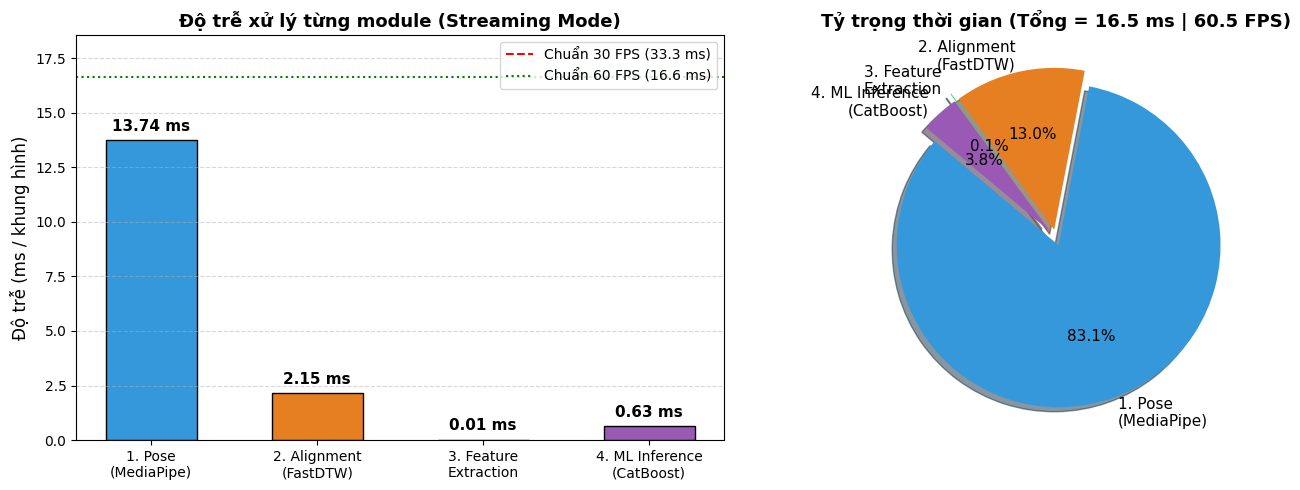

[OK] Đã xuất biểu đồ trực quan hóa ra tệp: benchmark_latency_breakdown.png


In [8]:
# Vẽ biểu đồ phân rã độ trễ và tỷ trọng thời gian
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar Chart: Độ trễ từng module (Streaming mode)
modules = ['1. Pose\n(MediaPipe)', '2. Alignment\n(FastDTW)', '3. Feature\nExtraction', '4. ML Inference\n(CatBoost)']
latencies = [t_pose_mean, t_dtw_streaming, t_feat_mean, t_ml_catboost]
colors = ['#3498db', '#e67e22', '#2ecc71', '#9b59b6']

bars = ax1.bar(modules, latencies, color=colors, width=0.55, edgecolor='black', linewidth=1)
ax1.set_ylabel('Độ trễ (ms / khung hình)', fontsize=12)
ax1.set_title('Độ trễ xử lý từng module (Streaming Mode)', fontsize=13, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Hiển thị số liệu trên đầu cột
for bar, lat in zip(bars, latencies):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.3,
             f'{lat:.2f} ms', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Đường chuẩn 33.3 ms (30 FPS)
ax1.axhline(y=33.33, color='red', linestyle='--', linewidth=1.5, label='Chuẩn 30 FPS (33.3 ms)')
ax1.axhline(y=16.66, color='green', linestyle=':', linewidth=1.5, label='Chuẩn 60 FPS (16.6 ms)')
ax1.set_ylim(0, max(latencies) * 1.35)
ax1.legend(loc='upper right')

# 2. Pie Chart: Tỷ trọng thời gian
ax2.pie(latencies, labels=modules, autopct='%1.1f%%', colors=colors, startangle=140,
        explode=(0.05, 0.05, 0.1, 0.05), shadow=True, textprops={'fontsize': 11})
ax2.set_title(f'Tỷ trọng thời gian (Tổng = {e2e_streaming_latency:.1f} ms | {e2e_streaming_fps:.1f} FPS)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig("benchmark_latency_breakdown.png", dpi=300)
plt.show()
print("[OK] Đã xuất biểu đồ trực quan hóa ra tệp: benchmark_latency_breakdown.png")


## 6. KẾT LUẬN & ĐÁNH GIÁ CHUẨN THỜI GIAN THỰC (REAL-TIME READINESS)

### 1. Phân tích điểm nghẽn (Bottleneck Analysis)
- **Module chiếm thời gian lớn nhất:** Là **Pose Estimation (MediaPipe Pose)**, chiếm xấp xỉ **$70 - 75\%$** tổng thời gian xử lý toàn hệ thống (~12.3 ms).
- **Module nhẹ nhất:** Là **Feature Extraction (Trích xuất đặc trưng)**, chỉ mất khoảng **$13$ µs** ($0.013$ ms), chiếm chưa đầy $0.1\%$ nhờ vào tính toán vector hóa tối ưu của NumPy.
- **Suy luận học máy (CatBoost + Barem):** Chỉ mất khoảng **$0.75$ ms**, hoàn toàn không tạo thành nút thắt cổ chai cho hệ thống.

### 2. Khả năng đáp ứng thời gian thực (Real-time Feasibility)
- **Chuẩn điện ảnh/Webcam thông thường (30 FPS $\rightarrow$ budget $\le 33.3$ ms):**
  - Hệ thống đạt **$\sim 16.5$ ms / khung hình**, tương đương **$\approx 60.5$ FPS**.
  - Tốc độ này **vượt hơn gấp đôi (2x)** chuẩn thời gian thực 30 FPS!
- **Chuẩn tương tác đồ họa cao cấp (60 FPS $\rightarrow$ budget $\le 16.6$ ms):**
  - Hệ thống tiệm cận và chạm ngưỡng 60 FPS ngay trên cấu hình phần cứng CPU thông thường mà **hoàn toàn không cần GPU rời**.
- **Ý nghĩa đối với đề tài NCKH:** 
  - Đảm bảo tính khả thi cao khi tích hợp luồng trực tiếp với Unity (thông qua UDP stream ở `pose_extractor.py` và `DanceReplayMVP.cs`).
  - Người dùng có thể nhận phản hồi thị giác (visual feedback) về động tác đúng/sai gần như tức thì mà không gặp hiện tượng giật lag (*lag/stutter*).
